In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy 
from plotting_helper import *
from parameters import *
%matplotlib inline

figures_path = 'figures/'
palette = plt.rcParams['axes.prop_cycle'].by_key()['color']  

In [2]:
def diff_assump(parameters, state_var, dt , elong_fun):

    
    x_vec = state_var[0]   #free mRNA concentrations
    xr_vec = state_var[1]  # bound mRNA ribosome concentrations
    y_vec = state_var[2]   #protein concentrations
    r = parameters['R'] - np.sum(xr_vec)  #concentration of free ribosomes


    new_x_vec = x_vec + dt * (-parameters['α']    * r * x_vec  + parameters['β']* xr_vec)
    new_xr_vec = xr_vec + dt * (parameters['α'] * r *  x_vec - parameters['β'] * xr_vec)
    new_y_vec = y_vec + dt * (parameters['β']  * xr_vec - parameters['γ'] * y_vec)

    return new_x_vec, new_xr_vec, new_y_vec


In [3]:
sim_time = 750
dt = 0.001

In [4]:
sampling = 1000 #resolution of recorded data points to check equilibrium state
results_lp = np.zeros([Rs.shape[0], int(sim_time/dt/sampling),3,N])

 
#prepare parameter dictionary
parameters = dict()
parameters['α'] = α
parameters['β'] = α/l_samples
parameters['γ'] = γ
parameters['l'] = l_samples
parameters['lp'] = stiffness_fun(parameters['l'],stiffness_fac)


x0 = np.ones([N])*x_init
init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]
    res = simulation_wrapper(init_state,parameters,diff_assump,R_fernandes, sim_time, dt, [True, sampling]) 
    results_lp[r]= res

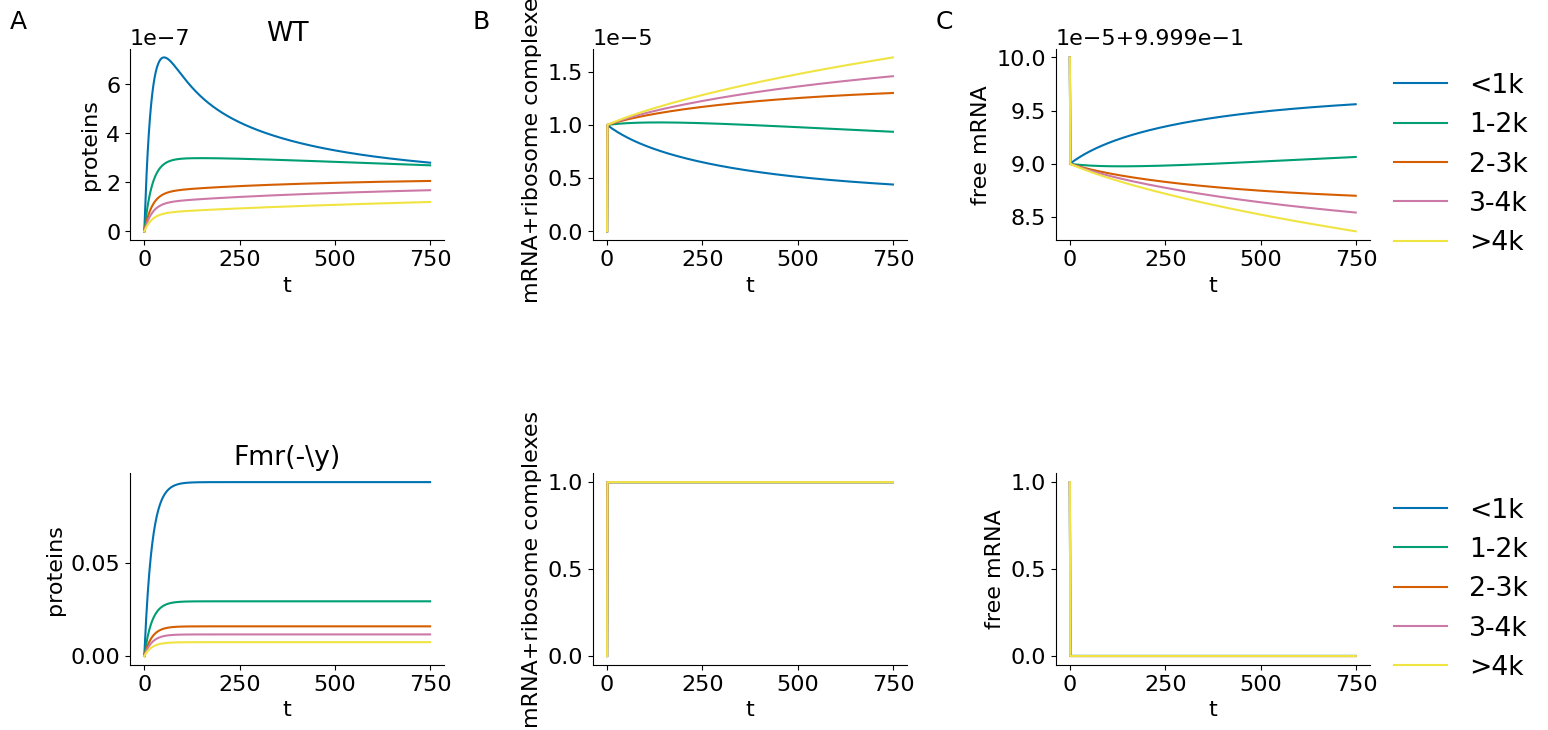

In [5]:
#check that all variables reach their equilibrium state (at minimal and maximal ribosome concetration)

layout = '''
    AABBC
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [1,0.2,1,0.2,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()

ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']
ribo_state= ['WT', 'Fmr(-\y)']
ribo_ind = [0,-1]

for j in range(2): 
    for i in range(3): 
        ax = fig.add_subplot(gs[j*2,i*2])
        if i ==0: 
            ax.set_title(ribo_state[j])
        av1 = np.mean(results_lp[ribo_ind[j],:,2-i,s_1k], axis = 0)
        av2 = np.mean(results_lp[ribo_ind[j],:,2-i,s_2k], axis = 0)
        av3 = np.mean(results_lp[ribo_ind[j],:,2-i,s_3k], axis = 0)
        av4 = np.mean(results_lp[ribo_ind[j],:,2-i,s_4k], axis = 0)
        av5 = np.mean(results_lp[ribo_ind[j],:,2-i,b_4k], axis = 0)

        ax.plot(np.arange(0,sim_time,dt*sampling), av1, label = '<1k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av2, label = '1-2k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av3, label = '2-3k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av4, label = '3-4k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av5, label = '>4k')
        ax.set_xlabel('t')
        ax.set_ylabel(ylabels[i])
        if i == 2: 
            ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
        clear_axes(ax)

plt.show()




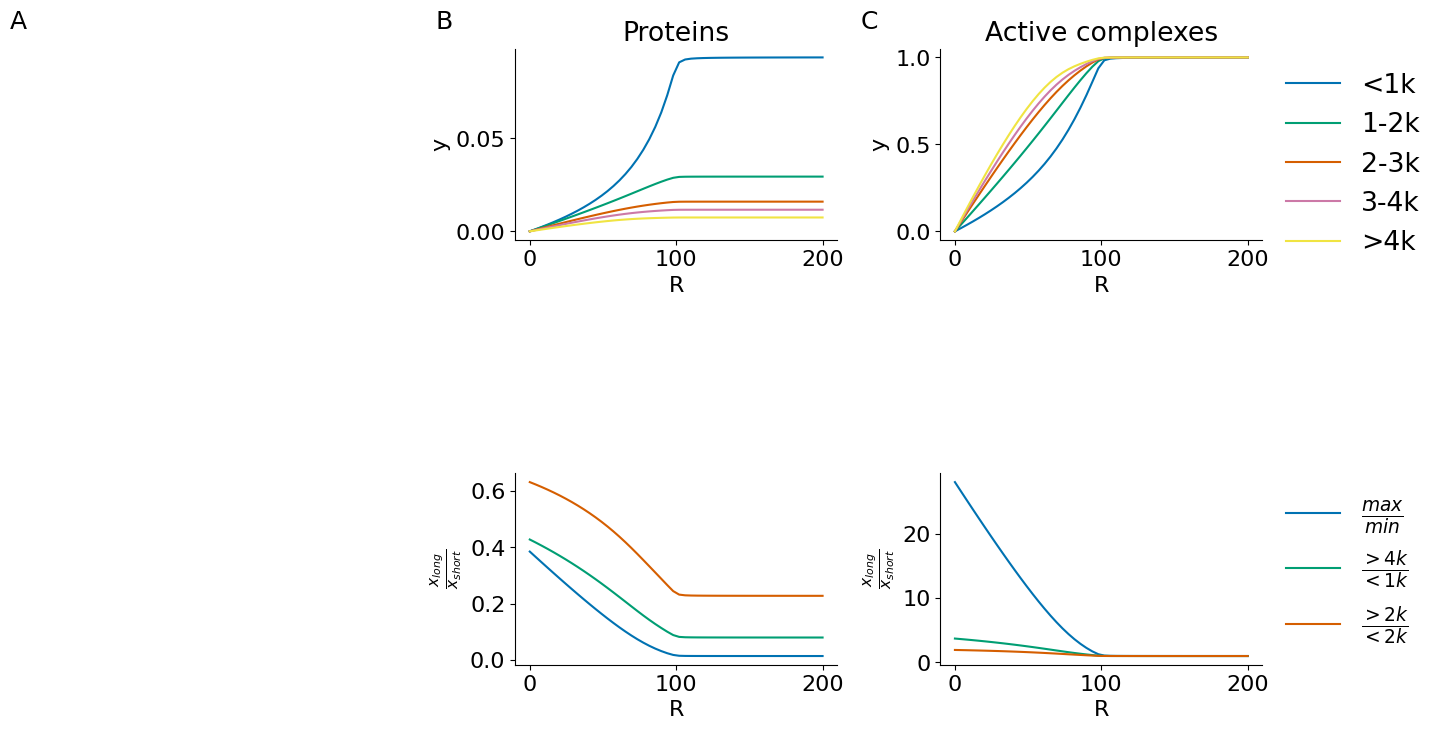

In [6]:
#figure for publication

layout = '''
    AABBCC
    AABBCC
    AABBCC
    '''



fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1, 1]
width_ratios = [1,0.1,1,0.1,1,0.1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=.8)
for a in list('ABC'):
    axes[a].set_axis_off()
                 

ax = fig.add_subplot(gs[0,2])
av1 = np.mean(results_lp[:,-1, 2,s_1k], axis = 1)
av2 = np.mean(results_lp[:,-1, 2,s_2k], axis = 1)
av3 = np.mean(results_lp[:,-1, 2,s_3k], axis = 1)
av4 = np.mean(results_lp[:,-1, 2,s_4k], axis = 1)
av5 = np.mean(results_lp[:,-1, 2,b_4k], axis = 1)

ax.plot(Rs, av1, label = '<1k')
ax.plot(Rs, av2, label = '1-2k')
ax.plot(Rs, av3, label = '2-3k')
ax.plot(Rs, av4, label = '3-4k')
ax.plot(Rs, av5, label = '>4k')
ax.set_ylabel('y')
ax.set_xlabel('R')
ax.set_title('Proteins')
clear_axes(ax)

ax = fig.add_subplot(gs[0,4])
av1 = np.mean(results_lp[:,-1, 1,s_1k], axis = 1)
av2 = np.mean(results_lp[:,-1, 1,s_2k], axis = 1)
av3 = np.mean(results_lp[:,-1, 1,s_3k], axis = 1)
av4 = np.mean(results_lp[:,-1, 1,s_4k], axis = 1)
av5 = np.mean(results_lp[:,-1, 1,b_4k], axis = 1)

ax.plot(Rs, av1, label = '<1k')
ax.plot(Rs, av2, label = '1-2k')
ax.plot(Rs, av3, label = '2-3k')
ax.plot(Rs, av4, label = '3-4k')
ax.plot(Rs, av5, label = '>4k')
ax.set_ylabel('y')
ax.set_xlabel('R')
ax.set_title('Active complexes')
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)


ax = fig.add_subplot(gs[2,2])
ax.plot(Rs, results_lp[:,-1,2,-1]/results_lp[:,-1,2,0], label = '$\\frac{max}{min}$', color = palette[0])
ax.plot(Rs, np.mean(results_lp[:,-1,2,b_4k], axis = 1)/np.mean(results_lp[:,-1,2,s_1k], axis = 1), label = '$\\frac{>4k}{<1k}$', color = palette[1])
ax.plot(Rs, np.mean(results_lp[:,-1,2,long_ind], axis = 1)/np.mean(results_lp[:,-1,2,short_ind], axis = 1), label = '\\frac{>4k}{<1k}', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
clear_axes(ax)

ax = fig.add_subplot(gs[2,4])
ax.plot(Rs, results_lp[:,-1,1,-1]/results_lp[:,-1,1,0], label = '$\\frac{max}{min}$', color = palette[0])
ax.plot(Rs, np.mean(results_lp[:,-1,1,b_4k], axis = 1)/np.mean(results_lp[:,-1,1,s_1k], axis = 1), label = '$\\frac{>4k}{<1k}$', color = palette[1])
ax.plot(Rs, np.mean(results_lp[:,-1,1,long_ind], axis = 1)/np.mean(results_lp[:,-1,1,short_ind], axis = 1), label = '$\\frac{>2k}{<2k}$', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)


plt.savefig(figures_path+'fig3_diff_ribo_competition.pdf')               
plt.show()



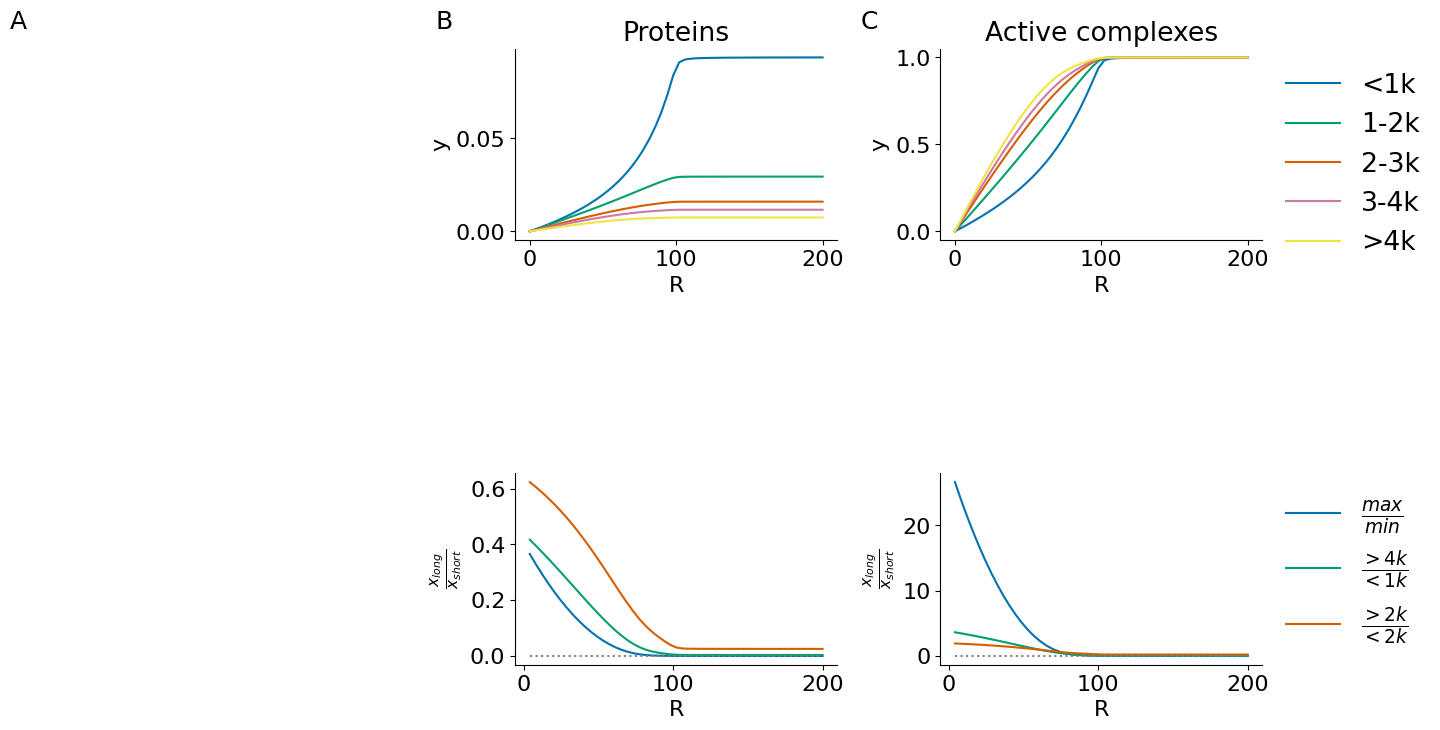

In [16]:
def calc_comp_score(dat1,dat2, diff_axis, mean_axis): 
    
    #compute differences along correct axis
    differences_along_R1= np.diff(dat1, axis = diff_axis)
    differences_along_R1[np.abs(differences_along_R1) < 1e-10] = np.nan
    differences_along_R2= np.diff(dat2, axis = diff_axis)
    differences_along_R2[np.abs(differences_along_R2) < 1e-10] = np.nan
    #comput the mean
    if mean_axis >= 0:
        means1 = np.nanmean(differences_along_R1, axis = mean_axis)
        means2 = np.nanmean(differences_along_R2, axis = mean_axis)
        return means1/means2
    else: 
        return differences_along_R1/differences_along_R2


#figure for publication

layout = '''
    AABBCC
    AABBCC
    AABBCC
    '''



fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1, 1]
width_ratios = [1,0.1,1,0.1,1,0.1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=.8)
for a in list('ABC'):
    axes[a].set_axis_off()
                 

ax = fig.add_subplot(gs[0,2])
av1 = np.mean(results_lp[:,-1, 2,s_1k], axis = 1)
av2 = np.mean(results_lp[:,-1, 2,s_2k], axis = 1)
av3 = np.mean(results_lp[:,-1, 2,s_3k], axis = 1)
av4 = np.mean(results_lp[:,-1, 2,s_4k], axis = 1)
av5 = np.mean(results_lp[:,-1, 2,b_4k], axis = 1)

ax.plot(Rs, av1, label = '<1k')
ax.plot(Rs, av2, label = '1-2k')
ax.plot(Rs, av3, label = '2-3k')
ax.plot(Rs, av4, label = '3-4k')
ax.plot(Rs, av5, label = '>4k')
ax.set_ylabel('y')
ax.set_xlabel('R')
ax.set_title('Proteins')
clear_axes(ax)

ax = fig.add_subplot(gs[0,4])
av1 = np.mean(results_lp[:,-1, 1,s_1k], axis = 1)
av2 = np.mean(results_lp[:,-1, 1,s_2k], axis = 1)
av3 = np.mean(results_lp[:,-1, 1,s_3k], axis = 1)
av4 = np.mean(results_lp[:,-1, 1,s_4k], axis = 1)
av5 = np.mean(results_lp[:,-1, 1,b_4k], axis = 1)

ax.plot(Rs, av1, label = '<1k')
ax.plot(Rs, av2, label = '1-2k')
ax.plot(Rs, av3, label = '2-3k')
ax.plot(Rs, av4, label = '3-4k')
ax.plot(Rs, av5, label = '>4k')
ax.set_ylabel('y')
ax.set_xlabel('R')
ax.set_title('Active complexes')
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)


ax = fig.add_subplot(gs[2,2])
ax.plot(Rs[1:], calc_comp_score(results_lp[:,-1,2,-1],results_lp[:,-1,2,0], diff_axis = 0, mean_axis = -1) ,label = '$\\frac{max}{min}$', color = palette[0])
ax.plot(Rs[1:], calc_comp_score(results_lp[:,-1,2,b_4k], results_lp[:,-1,2,s_1k], diff_axis= 0, mean_axis = 1), label = '$\\frac{>4k}{<1k}$', color = palette[1])
ax.plot(Rs[1:], calc_comp_score(results_lp[:,-1,2,long_ind],results_lp[:,-1,2,short_ind], diff_axis = 0, mean_axis = 1), label = '$\\frac{>2k}{21k}$', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
ax.plot(Rs[1:], Rs[1:]*0, linestyle = ':', color = 'grey')
clear_axes(ax)

ax = fig.add_subplot(gs[2,4])
ax.plot(Rs[1:], calc_comp_score(results_lp[:,-1,1,-1],results_lp[:,-1,1,0], diff_axis = 0, mean_axis = -1), label = '$\\frac{max}{min}$', color = palette[0])
ax.plot(Rs[1:], calc_comp_score(results_lp[:,-1,1,b_4k], results_lp[:,-1,1,s_1k], diff_axis= 0, mean_axis = 1), label = '$\\frac{>4k}{<1k}$', color = palette[1])
ax.plot(Rs[1:], calc_comp_score(results_lp[:,-1,1,long_ind],results_lp[:,-1,1,short_ind], diff_axis = 0, mean_axis = 1), label = '$\\frac{>2k}{<2k}$', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
ax.plot(Rs[1:], Rs[1:]*0, linestyle = ':', color = 'grey')
clear_axes(ax)


#plt.savefig(figures_path+'fig3_diff_ribo_competition.pdf')               
plt.show()



In [21]:
#parameter exploration here as well? 
def simulation_wrapper_parallel(params, sim_time, dt, Rs): 
    
    parameters = dict()
    parameters['α'] = params[0]
    parameters['β'] = params[1] / l_samples
    parameters['γ'] = γ
    parameters['l'] = l_samples
    parameters['lp'] = stiffness_fun(parameters['l'],stiffness_fac)
    parameters['Y_max'] =  N
    res = np.zeros([Rs.shape[0],3,N ])
    
    for r in range(Rs.shape[0]): 
        parameters['R'] = Rs[r]


        x0 = np.ones([N])*x_init
        init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 

        next_t = init_state

        for t in range(int(sim_time/dt)):
            next_t = diff_assump(parameters, next_t, dt, R_fernandes)
        res[r] = next_t

    return res

In [22]:
α_samples = np.linspace(0.0001, 0.1, 10) #this ensures that we will have cases in which α < β
β_samples = np.linspace(0.0001, 0.1, 12)

In [24]:
from joblib import Parallel, delayed

sim_time = 150 
dt = 0.001

results = Parallel(n_jobs=-1)(delayed(simulation_wrapper_parallel)([a,b], sim_time, dt,Rs) for a in α_samples for b in β_samples)
results = np.asarray(results)

In [25]:
results = np.reshape(results, (α_samples.shape[0], β_samples.shape[0], Rs.shape[0], 3, N))

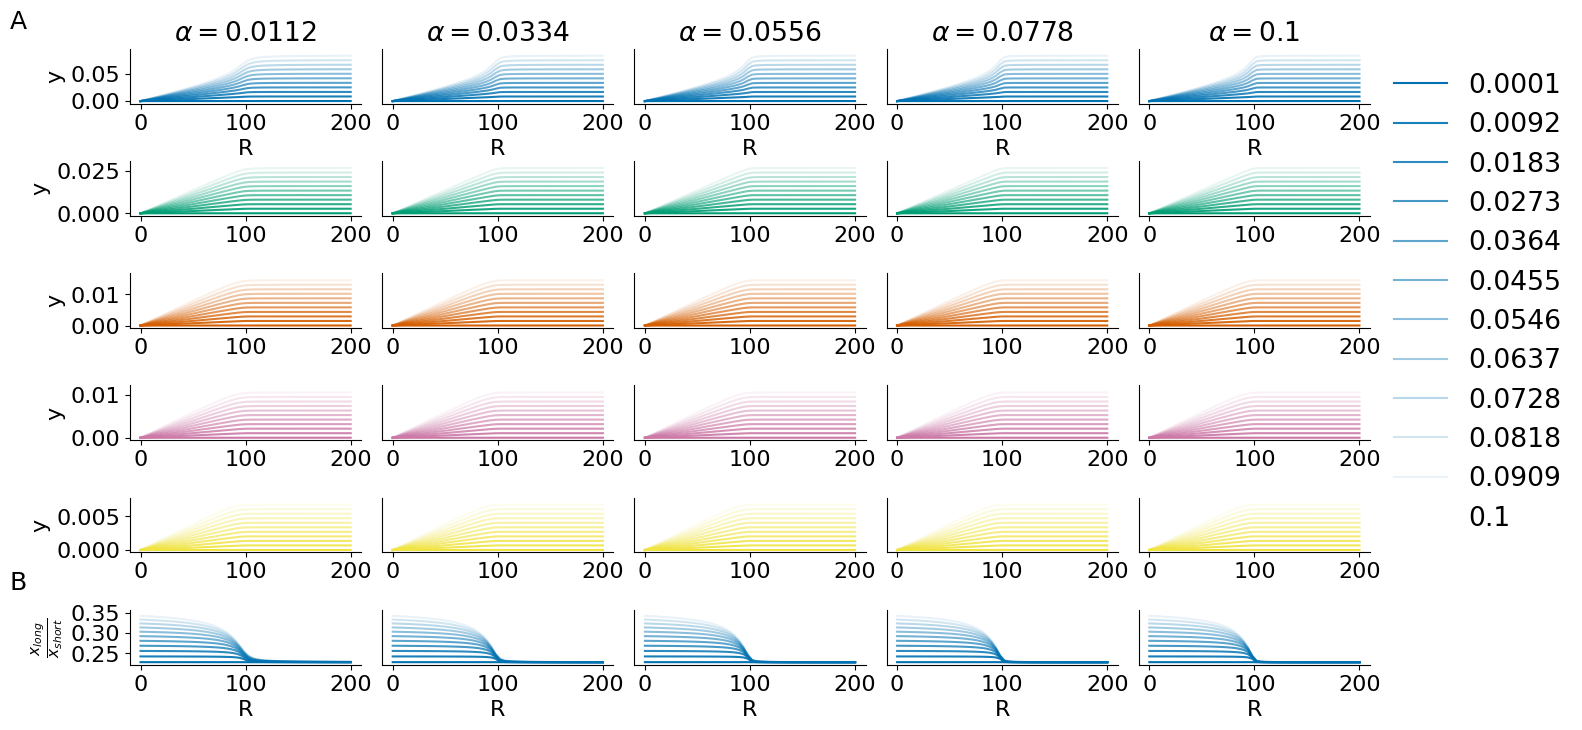

In [29]:
layout = '''
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    BBBBBBBBBB
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1,0.1,1,0.1,1,0.1,1,0.1,1]
width_ratios = [1,1,1,1,1,1,1,1,1,1]

specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'AB':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='AB', postfix='', offset_left=1.2)
for a in list('AB'):
    axes[a].set_axis_off()
    
ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']
avs = np.linspace(0,1, β_samples.shape[0])[::-1]

 
for i in range(1,α_samples.shape[0],2):
    ax1 = fig.add_subplot(gs[0,i-1:i+2-1])
    ax2 = fig.add_subplot(gs[2,i-1:i+2-1])
    ax3 = fig.add_subplot(gs[4,i-1:i+2-1])
    ax4 = fig.add_subplot(gs[6,i-1:i+2-1])
    ax5 = fig.add_subplot(gs[8,i-1:i+2-1])
    ax = fig.add_subplot(gs[10,i-1:i+2-1])
    for j in range(0,β_samples.shape[0]):
        av1 = np.mean(results[i ,j,:, 2,s_1k], axis = 0)
        av2 = np.mean(results[i,j,:, 2,s_2k], axis = 0)
        av3 = np.mean(results[i,j,:, 2,s_3k], axis = 0)
        av4 = np.mean(results[i,j,:, 2,s_4k], axis = 0)
        av5 = np.mean(results[i,j,:, 2,b_4k], axis = 0)
        
        rat1 = np.mean(results[i,j,:, 2,long_ind], axis = 0)/np.mean(results[i,j,:, 2,short_ind], axis = 0)

        ax1.plot(Rs, av1, label = np.round(β_samples[j],4), color= palette[0], alpha = avs[j])
        ax2.plot(Rs, av2, label = β_samples[j], color = palette[1], alpha = avs[j])
        ax3.plot(Rs, av3, label = β_samples[j], color = palette[2], alpha = avs[j])
        ax4.plot(Rs, av4, label = β_samples[j], color = palette[3], alpha = avs[j])
        ax5.plot(Rs, av5, label = β_samples[j], color =palette[4], alpha = avs[j])
        ax.plot(Rs, rat1, label = β_samples[j], color = palette[0], alpha = avs[j])
        #ax.plot(Rs, Rs*0 + 0.5, linestyle = ':', color = 'grey')
    ax1.set_title('$\\alpha =$'+str(np.round(α_samples[i],4)))
    #ax1.set_ylim(0,2)
    #ax2.set_ylim(0,0.75)
    #ax3.set_ylim(0,0.4)
    #ax4.set_ylim(0,0.3)
    #ax5.set_ylim(0,0.25)
    #ax.set_ylim(0.2,0.8)
    ax1.set_xlabel('R')
    ax.set_xlabel('R')
    
    if (i-1) > 0: 
        ax.set_yticks([])
        ax1.set_yticks([])
        ax2.set_yticks([])
        ax3.set_yticks([])
        ax4.set_yticks([])
        ax5.set_yticks([])
    else: 
        ax1.set_ylabel('y')
        ax2.set_ylabel('y')
        ax3.set_ylabel('y')
        ax4.set_ylabel('y')
        ax5.set_ylabel('y')
        ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
    

    clear_axes(ax)
    clear_axes(ax1)
    clear_axes(ax2)
    clear_axes(ax3)
    clear_axes(ax4)
    clear_axes(ax5)
handles, labels = ax.get_legend_handles_labels()
ax1.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
#plt.savefig(figures_path+'fig5_parameter_exploration.pdf')      
plt.show()



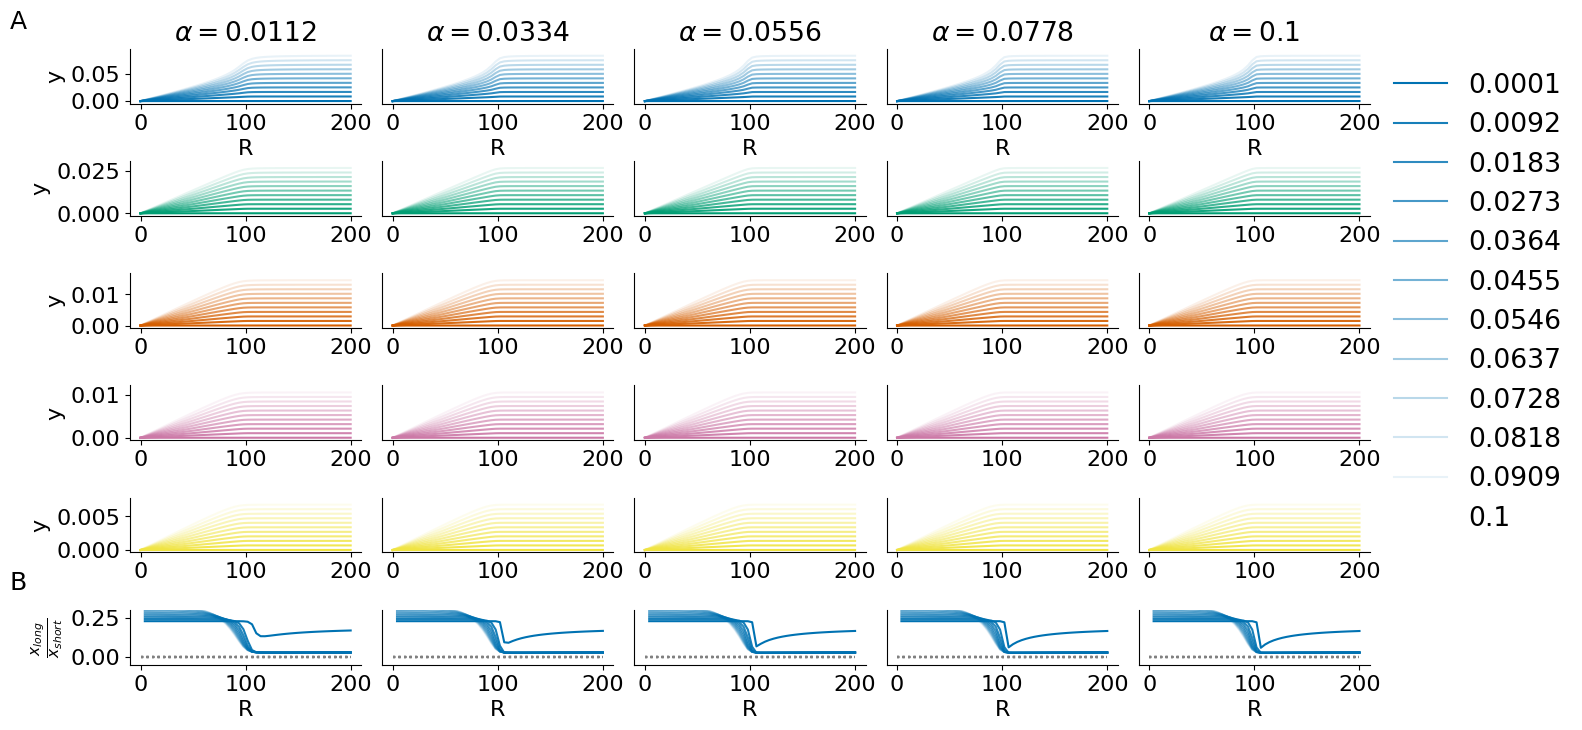

In [34]:
def calc_comp_score(dat1,dat2, diff_axis, mean_axis): 
    
    #compute differences along correct axis
    differences_along_R1= np.diff(dat1, axis = diff_axis)
    #differences_along_R1[np.abs(differences_along_R1) < 1e-10] = np.nan
    differences_along_R2= np.diff(dat2, axis = diff_axis)
    #differences_along_R2[np.abs(differences_along_R2) < 1e-10] = np.nan
    #comput the mean
    if mean_axis >= 0:
        means1 = np.nanmean(differences_along_R1, axis = mean_axis)
        means2 = np.nanmean(differences_along_R2, axis = mean_axis)
        return means1/means2
    else: 
        return differences_along_R1/differences_along_R2
    
    
    
layout = '''
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    BBBBBBBBBB
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1,0.1,1,0.1,1,0.1,1,0.1,1]
width_ratios = [1,1,1,1,1,1,1,1,1,1]

specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'AB':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='AB', postfix='', offset_left=1.2)
for a in list('AB'):
    axes[a].set_axis_off()
    
ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']
avs = np.linspace(0,1, β_samples.shape[0])[::-1]

 
for i in range(1,α_samples.shape[0],2):
    ax1 = fig.add_subplot(gs[0,i-1:i+2-1])
    ax2 = fig.add_subplot(gs[2,i-1:i+2-1])
    ax3 = fig.add_subplot(gs[4,i-1:i+2-1])
    ax4 = fig.add_subplot(gs[6,i-1:i+2-1])
    ax5 = fig.add_subplot(gs[8,i-1:i+2-1])
    ax = fig.add_subplot(gs[10,i-1:i+2-1])
    for j in range(0,β_samples.shape[0]):
        av1 = np.mean(results[i ,j,:, 2,s_1k], axis = 0)
        av2 = np.mean(results[i,j,:, 2,s_2k], axis = 0)
        av3 = np.mean(results[i,j,:, 2,s_3k], axis = 0)
        av4 = np.mean(results[i,j,:, 2,s_4k], axis = 0)
        av5 = np.mean(results[i,j,:, 2,b_4k], axis = 0)
        
        rat1 = calc_comp_score(results[i,j,:, 2,long_ind],results[i,j,:, 2,short_ind], diff_axis = 1, mean_axis = 0)

        ax1.plot(Rs, av1, label = np.round(β_samples[j],4), color= palette[0], alpha = avs[j])
        ax2.plot(Rs, av2, label = β_samples[j], color = palette[1], alpha = avs[j])
        ax3.plot(Rs, av3, label = β_samples[j], color = palette[2], alpha = avs[j])
        ax4.plot(Rs, av4, label = β_samples[j], color = palette[3], alpha = avs[j])
        ax5.plot(Rs, av5, label = β_samples[j], color =palette[4], alpha = avs[j])
        ax.plot(Rs[1:], rat1, label = β_samples[j], color = palette[0], alpha = avs[j])
        ax.plot(Rs, Rs*0, linestyle = ':', color = 'grey')
    ax1.set_title('$\\alpha =$'+str(np.round(α_samples[i],4)))
    #ax1.set_ylim(0,2)
    #ax2.set_ylim(0,0.75)
    #ax3.set_ylim(0,0.4)
    #ax4.set_ylim(0,0.3)
    #ax5.set_ylim(0,0.25)
    ax.set_ylim(-0.05,0.3)
    ax1.set_xlabel('R')
    ax.set_xlabel('R')
    
    if (i-1) > 0: 
        ax.set_yticks([])
        ax1.set_yticks([])
        ax2.set_yticks([])
        ax3.set_yticks([])
        ax4.set_yticks([])
        ax5.set_yticks([])
    else: 
        ax1.set_ylabel('y')
        ax2.set_ylabel('y')
        ax3.set_ylabel('y')
        ax4.set_ylabel('y')
        ax5.set_ylabel('y')
        ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
    

    clear_axes(ax)
    clear_axes(ax1)
    clear_axes(ax2)
    clear_axes(ax3)
    clear_axes(ax4)
    clear_axes(ax5)
handles, labels = ax.get_legend_handles_labels()
ax1.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
#plt.savefig(figures_path+'fig5_parameter_exploration.pdf')      
plt.show()



In [35]:
np.save('diff_data/ribosome_only_elongation_initiation_interaction.npz',results)